  Preparing metadata (setup.py) ... done
  Created wheel for minisom: filename=MiniSom-2.3.6-py3-none-any.whl size=13083 sha256=cf829be6e9145972a7813983f82d70fb7424cb0eba439b6c0e32faa1b9ed23c3
  Stored in directory: /root/.cache/pip/wheels/84/35/b8/48b06bd8cae7187916c28a29c6daa9e0ff610647a2dfa62b97
Successfully built minisom
Dataset shape: (1797, 64)
Number of classes: 10

First 10 BMU Coordinates:
[[3 0]
 [1 8]
 [7 8]
 [8 3]
 [0 6]
 [9 3]
 [4 9]
 [8 8]
 [3 8]
 [8 6]]

First 10 Cluster Labels:
[30 18 78 83  6 93 49 88 38 86]

Silhouette Score: 0.08882738669261152


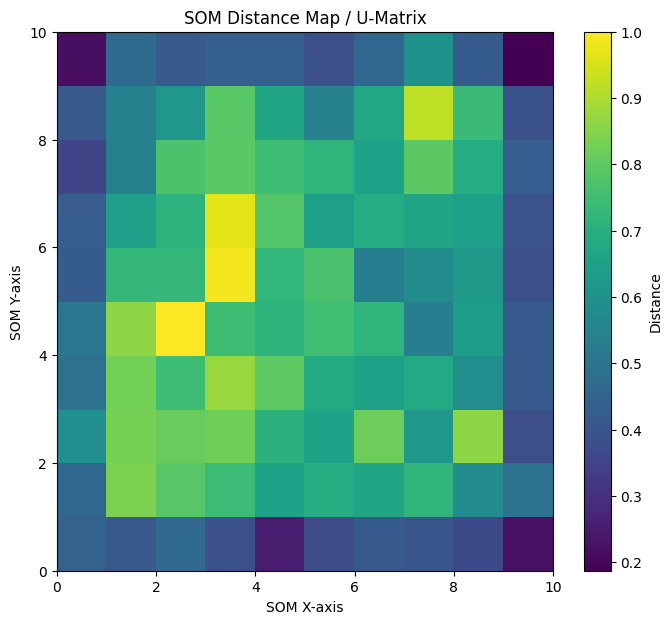

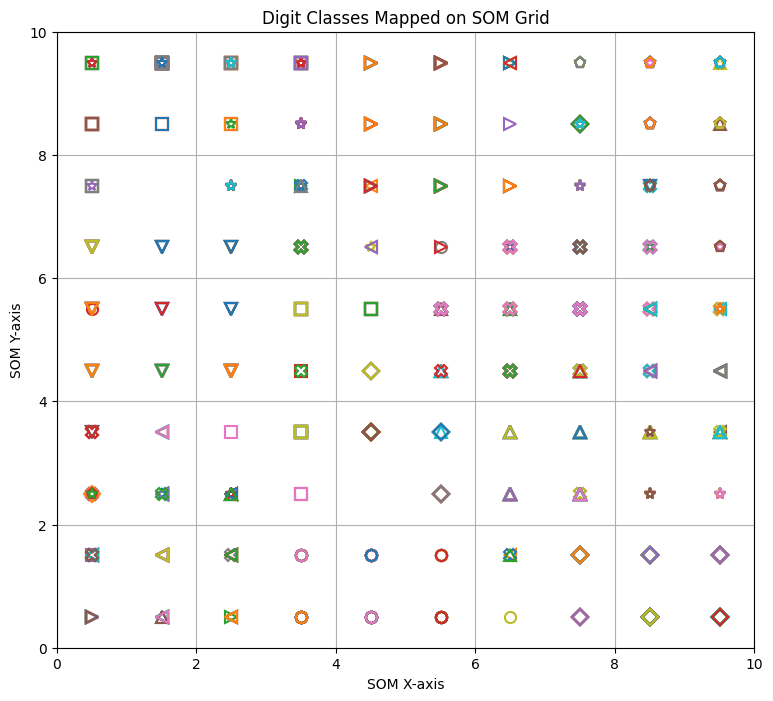


Result Table:
    Actual Digit  BMU X  BMU Y  Cluster Label
0              0      3      0             30
1              1      1      8             18
2              2      7      8             78
3              3      8      3             83
4              4      0      6              6
5              5      9      3             93
6              6      4      9             49
7              7      8      8             88
8              8      3      8             38
9              9      8      6             86
10             0      3      1             31
11             1      3      5             35
12             2      4      3             43
13             3      6      2             62
14             4      0      5              5


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
!pip install minisom

from sklearn.datasets import load_digits
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score
from minisom import MiniSom


digits = load_digits()
X = digits.data
y = digits.target

print("Dataset shape:", X.shape)
print("Number of classes:", len(np.unique(y)))


scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)


som_grid_rows = 10
som_grid_columns = 10

som = MiniSom(
    x=som_grid_rows,
    y=som_grid_columns,
    input_len=X_scaled.shape[1],
    sigma=1.0,
    learning_rate=0.5,
    random_seed=42
)


som.random_weights_init(X_scaled)


som.train_random(data=X_scaled, num_iteration=1000)


bmu_coordinates = np.array([som.winner(x) for x in X_scaled])


cluster_labels = np.array([
    coord[0] * som_grid_columns + coord[1]
    for coord in bmu_coordinates
])


print("\nFirst 10 BMU Coordinates:")
print(bmu_coordinates[:10])

print("\nFirst 10 Cluster Labels:")
print(cluster_labels[:10])


score = silhouette_score(X_scaled, cluster_labels)
print("\nSilhouette Score:", score)


plt.figure(figsize=(8, 7))
plt.pcolor(som.distance_map().T)
plt.colorbar(label="Distance")
plt.title("SOM Distance Map / U-Matrix")
plt.xlabel("SOM X-axis")
plt.ylabel("SOM Y-axis")
plt.show()


plt.figure(figsize=(9, 8))

markers = ['o', 's', 'D', '^', 'v', '<', '>', 'p', '*', 'X']

for i, x in enumerate(X_scaled):
    w = som.winner(x)
    plt.plot(
        w[0] + 0.5,
        w[1] + 0.5,
        markers[y[i]],
        markerfacecolor='None',
        markersize=8,
        markeredgewidth=1.5,
        label=str(y[i]) if i < 10 else ""
    )

plt.xlim([0, som_grid_rows])
plt.ylim([0, som_grid_columns])
plt.title("Digit Classes Mapped on SOM Grid")
plt.xlabel("SOM X-axis")
plt.ylabel("SOM Y-axis")
plt.grid()
plt.show()


result_df = pd.DataFrame({
    "Actual Digit": y,
    "BMU X": bmu_coordinates[:, 0],
    "BMU Y": bmu_coordinates[:, 1],
    "Cluster Label": cluster_labels
})

print("\nResult Table:")
print(result_df.head(15))